# Corporate Bankruptcy Prediction in R: Altman's Z-Score vs Logit, Elastic Net, Random Forests and XGBoost

> **What it does:** puts the 1968 benchmark of corporate credit scoring, **Altman's Z-score**, against modern statistical learning on 43,000 firm-years of Polish companies with 64 financial ratios.
> - **Classic scores:** Altman's Z′ for private firms, with its published coefficients and zones, and the same five ratios re-estimated by logistic regression.
> - **Models on all 64 ratios:** a logit, an elastic net (`glmnet`), a random forest (`ranger`) and gradient boosting (`xgboost`).
>
> The models are compared on discrimination, calibration and the cost of misclassification. Repeated stratified cross-validation and DeLong tests check whether the gains are real. The final test is **horizon**: a model fitted on one-year-ahead data has to warn two to five years before failure.
> **Data:** UCI *Polish Companies Bankruptcy* (Tomczak, 2016): 2000–2013, five forecasting horizons, 64 ratios per firm-year, bankrupt status at the end of the horizon.
> **Methods:** Altman Z′; logit; `glmnet` (α = 0.5, CV λ); `ranger` (500 trees, permutation importance); `xgboost` (early-stopped); `pROC` (DeLong); calibration by deciles; cost curves.
> **Key output:** AUC, PR-AUC and Brier by model with confidence intervals; how often Altman's "distress zone" is right; the ratios that matter beyond Altman's five; and how far ahead each model sees failure.

## 1. Altman's Z-score and why it is still the benchmark

Altman (1968) combined five accounting ratios with linear discriminant analysis. For **private firms** the revised **Z′** model replaces market equity with book equity:

$$Z' = 0.717\,\frac{\text{WC}}{\text{TA}} + 0.847\,\frac{\text{RE}}{\text{TA}} + 3.107\,\frac{\text{EBIT}}{\text{TA}} + 0.420\,\frac{\text{BE}}{\text{TL}} + 0.998\,\frac{\text{Sales}}{\text{TA}}$$

The ratios are:
- WC/TA: working capital (liquidity);
- RE/TA: retained earnings (age and cumulative profitability);
- EBIT/TA: operating profitability;
- BE/TL: book equity over total liabilities (leverage cushion);
- Sales/TA: asset turnover.

The zones are **distress** ($Z'<1.23$), **grey** (1.23–2.90) and **safe** ($>2.90$).

It survives because it is transparent, needs only a balance sheet and an income statement, and is surprisingly hard to beat by much. The question here is how much 64 ratios and non-linear learners add, and whether that gain holds further from the default date.

## 2. Setup

In [1]:
# --- Packages (install once with `Rscript install_packages.R` from the repo root) ------------
suppressPackageStartupMessages({
  library(tidyverse)
  library(scales)
  library(patchwork)
  library(plotly)
  library(htmlwidgets)
  library(jsonlite)
})
options(warn = 1, dplyr.summarise.inform = FALSE, repr.plot.width = 14, repr.plot.height = 5, repr.plot.res = 110)
options(crayon.enabled = FALSE, cli.num_colors = 1)      # plain-text tables in the notebook (no ANSI colour codes)

# --- Folders and credentials --------------------------------------------------------------
PROJECT_DIR <- getwd()
DATA_DIR <- file.path(PROJECT_DIR, "data"); OUT_DIR <- file.path(PROJECT_DIR, "outputs")
dir.create(DATA_DIR, showWarnings = FALSE); dir.create(OUT_DIR, showWarnings = FALSE)
find_env <- function(start = getwd()) {            # look for .env in this folder and its parents (like python-dotenv)
  d <- normalizePath(start)
  repeat {
    f <- file.path(d, ".env")
    if (file.exists(f)) return(f)
    parent <- dirname(d)
    if (parent == d) return(NA_character_)
    d <- parent
  }
}
env_file <- find_env()
if (!is.na(env_file)) suppressWarnings(dotenv::load_dot_env(env_file))   # tolerate a missing final newline

# --- Cache helper: every download is stored in data/ and reused for 12 hours ----------------
cached <- function(name, fetch, max_age_hours = 12) {
  path <- file.path(DATA_DIR, paste0(name, ".rds"))
  if (file.exists(path) && difftime(Sys.time(), file.mtime(path), units = "hours") < max_age_hours) return(readRDS(path))
  out <- tryCatch(fetch(), error = function(e) {
    if (file.exists(path)) { message(name, ": download failed (", conditionMessage(e), "); using cached copy"); return(readRDS(path)) }
    stop(e)
  })
  saveRDS(out, path)
  out
}

# --- Chart style (consistent palette across all charts) -----------------------------------
PALETTE <- c("#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948")
INK <- "#0b0b0b"; INK_2 <- "#52514e"; GRID <- "#e4e3df"; SURFACE <- "#fcfcfb"
STATUS <- c(green = "#1baf7a", amber = "#eda100", red = "#e34948")
theme_risk <- function() {
  theme_minimal(base_size = 11) +
    theme(plot.background = element_rect(fill = SURFACE, colour = NA), panel.background = element_rect(fill = SURFACE, colour = NA),
          panel.grid.major = element_line(colour = GRID), panel.grid.minor = element_blank(),
          plot.title = element_text(face = "bold", colour = INK, size = 12), plot.title.position = "plot",
          axis.text = element_text(colour = INK_2), axis.title = element_text(colour = INK_2),
          legend.position = "top", legend.title = element_blank())
}
theme_set(theme_risk())
save_fig <- function(p, name, width = 14, height = 5) ggsave(file.path(OUT_DIR, paste0(name, ".png")), p, width = width, height = height, dpi = 150, bg = SURFACE)

# Interactive dashboard as a single HTML file that loads plotly.js from a CDN (no pandoc needed)
save_plotly_html <- function(widget, name, title) {
  b <- plotly_build(widget)$x
  if (is.null(b$layout$height)) b$layout$height <- 900
  html <- sprintf('<!doctype html><html><head><meta charset="utf-8"><title>%s</title>
<script src="https://cdn.plot.ly/plotly-2.35.2.min.js"></script></head>
<body style="background:%s;margin:0"><div id="dash" style="width:100%%;height:95vh"></div>
<script>var fig=%s;Plotly.newPlot("dash",fig.data,fig.layout,{responsive:true});</script></body></html>',
                  title, SURFACE, toJSON(list(data = b$data, layout = b$layout), auto_unbox = TRUE, null = "null", na = "null", force = TRUE, digits = NA))
  writeLines(html, file.path(OUT_DIR, paste0(name, ".html")))
  message("Dashboard saved: outputs/", name, ".html")
}

suppressPackageStartupMessages({
  library(httr2)
  library(glmnet)
  library(ranger)
  library(xgboost)
  library(pROC)
})
set.seed(21)
N_FOLDS <- 5; N_REPEATS <- 3
UCI_ZIP <- "https://archive.ics.uci.edu/static/public/365/polish+companies+bankruptcy+data.zip"
cat(sprintf("R %s · glmnet %s · ranger %s · xgboost %s · pROC %s · run on %s\n", getRversion(), packageVersion("glmnet"),
            packageVersion("ranger"), packageVersion("xgboost"), packageVersion("pROC"), Sys.Date()))

R 4.3.3 · glmnet 5.1 · ranger 0.18.0 · xgboost 3.2.1.1 · pROC 1.18.5 · run on 2026-10-20


## 3. Data

The UCI archive holds five ARFF files. File $k$ contains ratios from the $k$-th year of the sample period, and the label says whether the firm went bankrupt **within $6-k$ years**. So `5year.arff` is the 1-year horizon and `1year.arff` the 5-year horizon.

- A small reader parses the ARFF text, with `?` as missing.
- Ratios are **winsorised at the 1st/99th percentile** (accounting ratios have extreme tails from tiny denominators).
- Missing values get the training median plus a missing flag for the variables with more than 5% missing.

Attribute meanings follow the UCI documentation. The five Altman ratios are attributes 3, 6, 7, 8 and 9.

In [2]:
read_arff <- function(path) {
  lines <- readLines(path, warn = FALSE)
  start <- which(tolower(trimws(lines)) == "@data")
  att <- sub("^@attribute\\s+(\\S+).*$", "\\1", grep("^@attribute", lines, value = TRUE, ignore.case = TRUE), ignore.case = TRUE)
  body <- lines[(start + 1):length(lines)]; body <- body[nzchar(trimws(body))]
  m <- read.csv(text = body, header = FALSE, na.strings = "?", col.names = att, stringsAsFactors = FALSE)
  m
}
raw <- cached("polish_bankruptcy", function() {
  tmp <- tempfile(fileext = ".zip"); request(UCI_ZIP) |> req_timeout(180) |> req_perform(path = tmp)
  ex <- tempfile(); unzip(tmp, exdir = ex)
  map_dfr(1:5, function(k) read_arff(file.path(ex, paste0(k, "year.arff"))) |> mutate(horizon = 6 - k))
}, max_age_hours = 24 * 365)
names(raw) <- c(paste0("X", 1:64), "bankrupt", "horizon")
raw$bankrupt <- as.integer(raw$bankrupt)
LABELS <- c(X1 = "net profit / TA", X2 = "total liabilities / TA", X3 = "working capital / TA", X4 = "current ratio",
            X5 = "cash interval (days)", X6 = "retained earnings / TA", X7 = "EBIT / TA", X8 = "book equity / TL", X9 = "sales / TA",
            X10 = "equity / TA", X13 = "(gross profit + depr.) / sales", X16 = "(gross profit + depr.) / TL", X17 = "TA / TL", X21 = "sales growth", X22 = "operating profit / TA",
            X24 = "gross profit (3y) / TA", X25 = "(equity - share capital) / TA", X26 = "(net profit + depr.) / TL",
            X27 = "operating profit / financial expenses", X29 = "log total assets", X34 = "operating expenses / TL",
            X35 = "profit on sales / TA", X39 = "profit on sales / sales", X40 = "(current assets - inventory) / ST liabilities",
            X41 = "TL / ((op. profit + depr.) × 12/365)", X44 = "receivables × 365 / sales", X46 = "(CA - inventory) / ST liabilities",
            X56 = "(sales - COGS) / sales", X58 = "total costs / total sales", X61 = "sales / receivables", X64 = "sales / fixed assets")
lab <- function(v) {
  base <- sub("_na$", "", v)
  out <- ifelse(base %in% names(LABELS), paste0(base, " ", LABELS[base]), base)
  ifelse(grepl("_na$", v), paste0(out, " is missing"), out)
}
raw |> group_by(horizon) |> summarise(firm_years = n(), bankrupt = sum(bankrupt), rate = mean(bankrupt)) |> arrange(horizon)

horizon,firm_years,bankrupt,rate
<dbl>,<int>,<int>,<dbl>
1,5910,410,410
2,9792,515,515
3,10503,495,495
4,10173,400,400
5,7027,271,271


In [3]:
X_ALL <- paste0("X", 1:64)
ALTMAN <- c("X3", "X6", "X7", "X8", "X9")
prep <- function(train, test) {
  # winsorise + median-impute with training statistics, add missing flags for sparse variables
  out_tr <- train; out_te <- test
  miss_vars <- X_ALL[colMeans(is.na(train[X_ALL])) > 0.05]
  for (v in X_ALL) {
    q <- quantile(train[[v]], c(0.01, 0.99), na.rm = TRUE); med <- median(train[[v]], na.rm = TRUE)
    f <- function(x) { x <- pmin(pmax(x, q[1]), q[2]); x[is.na(x)] <- med; x }
    if (v %in% miss_vars) { out_tr[[paste0(v, "_na")]] <- as.integer(is.na(train[[v]])); out_te[[paste0(v, "_na")]] <- as.integer(is.na(test[[v]])) }
    out_tr[[v]] <- f(train[[v]]); out_te[[v]] <- f(test[[v]])
  }
  list(tr = out_tr, te = out_te, feats = c(X_ALL, paste0(miss_vars, "_na")))
}
altman_z <- function(d) 0.717 * d$X3 + 0.847 * d$X6 + 3.107 * d$X7 + 0.420 * d$X8 + 0.998 * d$X9
one_year <- raw |> filter(horizon == 1)
cat(sprintf("Main sample: 1-year horizon, %s firm-years, %s bankruptcies (%.1f%%)\n", comma(nrow(one_year)), sum(one_year$bankrupt), 100 * mean(one_year$bankrupt)))

Main sample: 1-year horizon, 5,910 firm-years, 410 bankruptcies (6.9%)


## 4. Six models, repeated cross-validation

All models use the same stratified folds: 5 folds × 3 repeats on the 1-year horizon. Inside each fold the preprocessing is fitted on the training part only.

| model | inputs | notes |
|---|---|---|
| **Altman Z′ (published)** | 5 ratios | no fitting; the score is $-Z'$ |
| **Altman ratios, logit** | 5 ratios | Altman's variables re-weighted for this population |
| **Logit, 64 ratios** | 64 + flags | plain maximum likelihood (some separation warnings are expected) |
| **Elastic net** | 64 + flags | `cv.glmnet`, α = 0.5, λ by inner 5-fold CV (λ_1se), standardised |
| **Random forest** | 64 + flags | `ranger`, 500 trees, mtry = √p, probability forest |
| **XGBoost** | 64 + flags | depth 4, η = 0.05, early stopping on an inner 20% split, `scale_pos_weight` = 1 to keep probabilities calibrated |

The metrics are:
- **AUC** (ranking);
- **PR-AUC** (precision at low default rates);
- **Brier score** (probability accuracy), not available for the published Z′, which is a score and not a probability.

Out-of-fold predictions from the first repeat are kept for the DeLong tests, calibration and the cost analysis.

In [4]:
pr_auc <- function(y, p) {                               # average precision
  o <- order(p, decreasing = TRUE); y <- y[o]
  tp <- cumsum(y); prec <- tp / seq_along(y)
  sum(prec[y == 1]) / sum(y)
}
fit_predict <- function(tr, te, feats) {
  y <- tr$bankrupt
  p <- list()
  p$`Altman Z′ (published)` <- -altman_z(te)
  m_alt <- suppressWarnings(glm(bankrupt ~ ., data = tr[c(ALTMAN, "bankrupt")], family = binomial))
  p$`Altman ratios, logit` <- predict(m_alt, te, type = "response")
  m_log <- suppressWarnings(glm(bankrupt ~ ., data = tr[c(feats, "bankrupt")], family = binomial, control = list(maxit = 100)))
  p$`Logit, 64 ratios` <- suppressWarnings(predict(m_log, te, type = "response"))
  Xtr <- as.matrix(tr[feats]); Xte <- as.matrix(te[feats])
  m_en <- cv.glmnet(Xtr, y, family = "binomial", alpha = 0.5, nfolds = 5)
  p$`Elastic net` <- as.numeric(predict(m_en, Xte, s = "lambda.1se", type = "response"))
  m_rf <- ranger(x = tr[feats], y = factor(y), num.trees = 500, probability = TRUE, min.node.size = 10, num.threads = 2, seed = 21)
  p$`Random forest` <- predict(m_rf, te[feats])$predictions[, "1"]
  idx <- sample(nrow(Xtr), round(0.8 * nrow(Xtr)))
  dtr <- xgb.DMatrix(Xtr[idx, ], label = y[idx]); dva <- xgb.DMatrix(Xtr[-idx, ], label = y[-idx])
  m_xg <- xgb.train(params = list(objective = "binary:logistic", eval_metric = "logloss", max_depth = 4, eta = 0.05, subsample = 0.8,
                                  colsample_bytree = 0.7, min_child_weight = 3, nthread = 2),
                    data = dtr, nrounds = 2000, evals = list(val = dva), early_stopping_rounds = 50, verbose = 0)
  p$XGBoost <- predict(m_xg, xgb.DMatrix(Xte))
  list(pred = p, models = list(en = m_en, rf = m_rf, xg = m_xg))
}

folds_for <- function(y, k, seed) { set.seed(seed); f <- integer(length(y))
  for (cl in 0:1) { i <- which(y == cl); f[i] <- sample(rep(1:k, length.out = length(i))) }; f }
MODELS <- c("Altman Z′ (published)", "Altman ratios, logit", "Logit, 64 ratios", "Elastic net", "Random forest", "XGBoost")
cv_rows <- list(); oof <- matrix(NA, nrow(one_year), length(MODELS), dimnames = list(NULL, MODELS))
t0 <- Sys.time()
for (r in 1:N_REPEATS) {
  f <- folds_for(one_year$bankrupt, N_FOLDS, 100 + r)
  for (k in 1:N_FOLDS) {
    pp <- prep(one_year[f != k, ], one_year[f == k, ])
    res <- fit_predict(pp$tr, pp$te, pp$feats)
    yk <- pp$te$bankrupt
    for (m in MODELS) {
      pk <- res$pred[[m]]
      cv_rows[[length(cv_rows) + 1]] <- tibble(rep = r, fold = k, model = m, auc = as.numeric(auc(roc(yk, pk, quiet = TRUE))),
                                               pr_auc = pr_auc(yk, pk), brier = if (m == MODELS[1]) NA else mean((pk - yk)^2))
      if (r == 1) oof[f == k, m] <- pk
    }
  }
}
cv <- bind_rows(cv_rows)
cat(sprintf("%d model fits in %.1f minutes\n", N_REPEATS * N_FOLDS * length(MODELS), as.numeric(difftime(Sys.time(), t0, units = "mins"))))
cv_tab <- cv |> group_by(model) |> summarise(AUC = mean(auc), AUC_sd = sd(auc), PR_AUC = mean(pr_auc), PR_AUC_sd = sd(pr_auc), Brier = mean(brier)) |>
  mutate(model = factor(model, MODELS)) |> arrange(model)
cv_tab |> mutate(across(where(is.numeric), ~ round(.x, 4)))

90 model fits in 2.6 minutes


model,AUC,AUC_sd,PR_AUC,PR_AUC_sd,Brier
<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Altman Z′ (published),0.7046,0.0353,0.2510,0.0373,NA
"Altman ratios, logit",0.7798,0.0245,0.3152,0.0353,0.0565
"Logit, 64 ratios",0.8775,0.0199,0.5123,0.0451,0.0453
Elastic net,0.8729,0.0184,0.4676,0.0326,0.0490
Random forest,0.9278,0.0075,0.6353,0.0343,0.0399
XGBoost,0.9522,0.0066,0.7779,0.0266,0.0295


## 5. Are the differences real? DeLong tests on out-of-fold predictions

Each model's out-of-fold ROC curve (first repeat) is compared with the published Z′ and with the best model, using DeLong's test for correlated ROC curves (same firms). The test tells whether an AUC gain is larger than the noise of a sample with about 400 bankruptcies.

In [5]:
y1 <- one_year$bankrupt
rocs <- map(MODELS, ~ roc(y1, oof[, .x], quiet = TRUE)) |> set_names(MODELS)
best <- MODELS[which.max(map_dbl(rocs, ~ as.numeric(auc(.x))))]
delong <- map_dfr(MODELS, function(m) {
  ci_ <- ci.auc(rocs[[m]], method = "delong")
  tibble(model = m, AUC_oof = as.numeric(auc(rocs[[m]])), CI_low = ci_[1], CI_high = ci_[3],
         p_vs_altman = if (m == MODELS[1]) NA else roc.test(rocs[[m]], rocs[[1]], method = "delong")$p.value,
         p_vs_best = if (m == best) NA else roc.test(rocs[[m]], rocs[[best]], method = "delong")$p.value)
})
cat("Best out-of-fold AUC:", best, "\n")
delong |> mutate(across(where(is.numeric), ~ signif(.x, 3)))

Best out-of-fold AUC: XGBoost 


model,AUC_oof,CI_low,CI_high,p_vs_altman,p_vs_best
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Altman Z′ (published),0.705,0.674,0.736,NA,2.87e-61
"Altman ratios, logit",0.781,0.754,0.808,1.10e-07,2.64e-41
"Logit, 64 ratios",0.878,0.857,0.898,9.11e-31,5.45e-16
Elastic net,0.874,0.855,0.894,4.43e-34,8.27e-21
Random forest,0.929,0.916,0.943,4.71e-52,5.70e-08
XGBoost,0.953,0.942,0.964,2.87e-61,NA


## 6. Altman's zones in practice, calibration and the cost of errors

**Zones.** How do firms in each Z′ zone actually fare? A score is only as useful as the action it triggers.

**Calibration.** The probability models' out-of-fold PDs are grouped into deciles and compared with observed rates.

**Cost of errors.** A credit decision misses a bankruptcy at a cost (a loss given default, say 60% of exposure) and rejects a good firm at another cost (forgone margin, say 5%). Missing a default is therefore about 12 times as costly. For each model the cut-off that minimises the total cost is found on the out-of-fold predictions, and the cost per 1,000 firms is compared.

In [6]:
z1 <- altman_z(prep(one_year, one_year)$tr)
zones <- tibble(z = z1, y = y1, zone = cut(z1, c(-Inf, 1.23, 2.90, Inf), labels = c("distress (<1.23)", "grey (1.23–2.90)", "safe (>2.90)"))) |>
  group_by(zone) |> summarise(firms = n(), share = n() / length(z1), bankrupt = sum(y), bankruptcy_rate = mean(y), share_of_all_bankruptcies = sum(y) / sum(y1))
COST_FN <- 0.60; COST_FP <- 0.05
cost_tab <- map_dfr(MODELS, function(m) {
  s <- oof[, m]; th <- quantile(s, seq(0.5, 0.995, by = 0.0025))
  costs <- map_dbl(th, function(t) { flag <- s >= t; (COST_FN * sum(!flag & y1 == 1) + COST_FP * sum(flag & y1 == 0)) / length(y1) * 1000 })
  i <- which.min(costs); flag <- s >= th[i]
  tibble(model = m, `flagged %` = mean(flag) * 100, `bankruptcies caught %` = mean(flag[y1 == 1]) * 100,
         `good firms rejected %` = mean(flag[y1 == 0]) * 100, `cost per 1,000 firms` = costs[i])
}) |> mutate(`saving vs Altman %` = (1 - `cost per 1,000 firms` / `cost per 1,000 firms`[1]) * 100)
calib <- map_dfr(MODELS[-1], function(m) tibble(model = m, p = oof[, m], y = y1) |> mutate(bin = ntile(p, 10)) |>
                   group_by(model, bin) |> summarise(pred = mean(p), obs = mean(y), n = n(), .groups = "drop"))
print(zones |> mutate(across(where(is.numeric), ~ round(.x, 3))))
cost_tab |> mutate(across(where(is.numeric), ~ round(.x, 2)))

# A tibble: 3 × 6
  zone             firms share bankrupt bankruptcy_rate share_of_all_bankruptc…¹
  <fct>            <dbl> <dbl>    <dbl>           <dbl>                    <dbl>
1 distress (<1.23)   856 0.145      187           0.218                    0.456
2 grey (1.23–2.90)  2634 0.446      134           0.051                    0.327
3 safe (>2.90)      2420 0.409       89           0.037                    0.217
# ℹ abbreviated name: ¹​share_of_all_bankruptcies


model,flagged %,bankruptcies caught %,good firms rejected %,"cost per 1,000 firms",saving vs Altman %
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Altman Z′ (published),22.50,56.59,19.96,27.36,0.00
"Altman ratios, logit",24.25,69.27,20.89,22.51,17.72
"Logit, 64 ratios",12.76,69.76,8.51,16.55,39.52
Elastic net,18.75,76.59,14.44,16.46,39.83
Random forest,16.75,82.93,11.82,12.61,53.93
XGBoost,16.01,88.05,10.64,9.92,63.73


## 7. What the learners see beyond Altman's five ratios

- **Random forest:** permutation importance from a forest fitted on the full 1-year sample.
- **XGBoost:** gain importance from the same fit.
- **Elastic net:** the standardised coefficients that survive the penalty.

Altman's five ratios are marked, to see whether the learners rediscover them or rely on something else.

In [7]:
pp_full <- prep(one_year, one_year)
feats <- pp_full$feats
rf_full <- ranger(x = pp_full$tr[feats], y = factor(y1), num.trees = 500, probability = TRUE, min.node.size = 10, importance = "permutation", num.threads = 2, seed = 21)
dfull <- xgb.DMatrix(as.matrix(pp_full$tr[feats]), label = y1)
xg_full <- xgb.train(params = list(objective = "binary:logistic", max_depth = 4, eta = 0.05, subsample = 0.8, colsample_bytree = 0.7, min_child_weight = 3, nthread = 2),
                     data = dfull, nrounds = 600, verbose = 0)
en_full <- cv.glmnet(scale(as.matrix(pp_full$tr[feats])), y1, family = "binomial", alpha = 0.5, nfolds = 5)
imp <- tibble(var = feats, rf = rf_full$variable.importance[feats]) |>
  left_join(xgb.importance(model = xg_full) |> as_tibble() |> transmute(var = Feature, xgb_gain = Gain), by = "var") |>
  left_join(tibble(var = feats, en_coef = as.numeric(coef(en_full, s = "lambda.1se"))[-1]), by = "var") |>
  mutate(xgb_gain = replace_na(xgb_gain, 0), altman = var %in% ALTMAN, rf_rank = rank(-rf), xgb_rank = rank(-xgb_gain)) |> arrange(rf_rank)
cat(sprintf("Elastic net keeps %d of %d variables; Altman ratios' best RF rank: %d; RF top-10 contains %d Altman ratios\n",
            sum(imp$en_coef != 0), length(feats), min(imp$rf_rank[imp$altman]), sum(imp$altman & imp$rf_rank <= 10)))
imp |> head(15) |> mutate(var = lab(var), across(where(is.numeric), ~ signif(.x, 3)))

Elastic net keeps 27 of 66 variables; Altman ratios' best RF rank: 11; RF top-10 contains 0 Altman ratios


var,rf,xgb_gain,en_coef,altman,rf_rank,xgb_rank
<chr>,<dbl>,<dbl>,<dbl>,<lgl>,<dbl>,<dbl>
X27 operating profit / financial expenses is missing,0.01580,0.073600,0.5210,FALSE,1,4
X46 (CA - inventory) / ST liabilities,0.01200,0.055800,0.0000,FALSE,2,6
X2 total liabilities / TA,0.01070,0.002000,0.0106,FALSE,3,59
X27 operating profit / financial expenses,0.01040,0.025000,0.0000,FALSE,4,10
X26 (net profit + depr.) / TL,0.01020,0.011000,-0.0579,FALSE,5,21
X16 (gross profit + depr.) / TL,0.00911,0.001860,0.0000,FALSE,6,60
X35 profit on sales / TA,0.00892,0.091200,-0.4590,FALSE,7,2
X39 profit on sales / sales,0.00824,0.075600,-0.2960,FALSE,8,3
X17 TA / TL,0.00772,0.002520,0.0000,FALSE,9,55


## 8. How far ahead can each model see failure?

Every model is refitted on the full 1-year sample and applied **unchanged** to the 2-, 3-, 4- and 5-year horizon files. These are different firm-years, labelled by bankruptcy within 2–5 years. AUC by horizon measures how early the warning comes.

The 1-year AUC here is in-sample for the fitted models. The cross-validated 1-year numbers are in §4; the other horizons are genuinely out of sample.

In [8]:
fits <- fit_predict(pp_full$tr, pp_full$tr[1:10, ], feats)$models
m_alt <- suppressWarnings(glm(bankrupt ~ ., data = pp_full$tr[c(ALTMAN, "bankrupt")], family = binomial))
m_log <- suppressWarnings(glm(bankrupt ~ ., data = pp_full$tr[c(feats, "bankrupt")], family = binomial, control = list(maxit = 100)))
hz <- map_dfr(2:5, function(h) {
  d <- raw |> filter(horizon == h); te <- prep(one_year, d)$te; yh <- d$bankrupt
  sc <- list(`Altman Z′ (published)` = -altman_z(te), `Altman ratios, logit` = predict(m_alt, te, type = "response"),
             `Logit, 64 ratios` = suppressWarnings(predict(m_log, te, type = "response")),
             `Elastic net` = as.numeric(predict(fits$en, as.matrix(te[feats]), s = "lambda.1se", type = "response")),
             `Random forest` = predict(fits$rf, te[feats])$predictions[, "1"], XGBoost = predict(fits$xg, xgb.DMatrix(as.matrix(te[feats]))))
  imap_dfr(sc, ~ tibble(horizon = h, model = .y, auc = as.numeric(auc(roc(yh, .x, quiet = TRUE))), n = length(yh), defaults = sum(yh)))
})
hz <- bind_rows(cv_tab |> transmute(horizon = 1L, model = as.character(model), auc = AUC, n = nrow(one_year), defaults = sum(y1)), hz)
hz |> select(horizon, model, auc) |> pivot_wider(names_from = horizon, values_from = auc, names_prefix = "h") |>
  mutate(model = factor(model, MODELS)) |> arrange(model) |> mutate(across(where(is.numeric), ~ round(.x, 3)))

model,h1,h2,h3,h4,h5
<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Altman Z′ (published),0.705,0.659,0.654,0.603,0.636
"Altman ratios, logit",0.780,0.707,0.687,0.640,0.691
"Logit, 64 ratios",0.878,0.822,0.812,0.802,0.870
Elastic net,0.873,0.786,0.780,0.771,0.833
Random forest,0.928,0.883,0.853,0.849,0.893
XGBoost,0.952,0.937,0.912,0.862,0.928


## 9. Charts

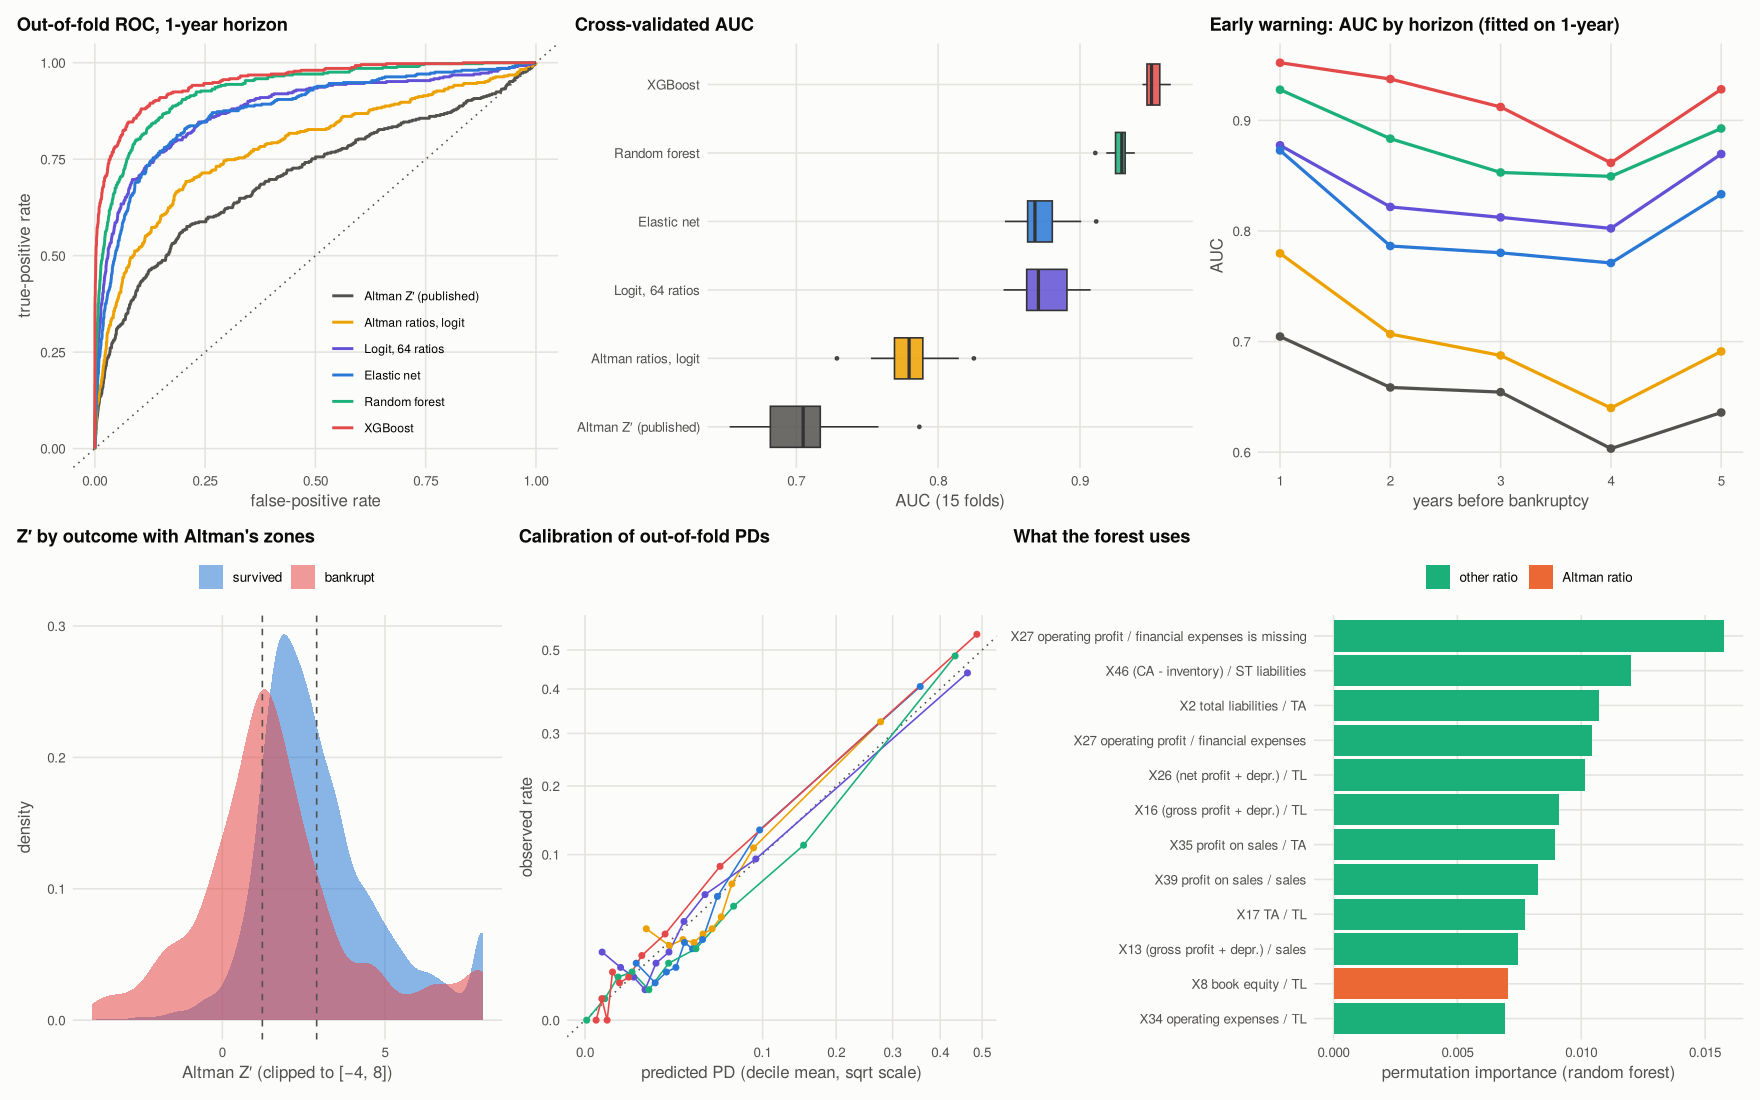

In [9]:
options(repr.plot.width = 16, repr.plot.height = 10)
cols <- setNames(c(INK_2, PALETTE[4], PALETTE[7], PALETTE[1], PALETTE[3], PALETTE[8]), MODELS)
roc_df <- imap_dfr(rocs, ~ tibble(model = .y, fpr = 1 - .x$specificities, tpr = .x$sensitivities)) |> mutate(model = factor(model, MODELS))
p1 <- ggplot(roc_df, aes(fpr, tpr, colour = model)) + geom_path(linewidth = 0.9) + geom_abline(linetype = "dotted", colour = INK_2) +
  scale_colour_manual(values = cols) + labs(x = "false-positive rate", y = "true-positive rate", title = "Out-of-fold ROC, 1-year horizon") +
  theme(legend.position = c(0.68, 0.25), legend.text = element_text(size = 8))
p2 <- ggplot(cv |> mutate(model = factor(model, MODELS)), aes(model, auc, fill = model)) + geom_boxplot(width = 0.6, outlier.size = 0.8, alpha = 0.85) +
  scale_fill_manual(values = cols) + guides(fill = "none") + coord_flip() + labs(x = NULL, y = "AUC (15 folds)", title = "Cross-validated AUC")
p3 <- ggplot(hz |> mutate(model = factor(model, MODELS)), aes(horizon, auc, colour = model)) + geom_line(linewidth = 1) + geom_point(size = 2) +
  scale_colour_manual(values = cols) + guides(colour = "none") + labs(x = "years before bankruptcy", y = "AUC", title = "Early warning: AUC by horizon (fitted on 1-year)")
p4 <- ggplot(tibble(z = pmin(pmax(z1, -4), 8), y = factor(y1, labels = c("survived", "bankrupt"))), aes(z, fill = y)) +
  geom_density(alpha = 0.55, colour = NA) + geom_vline(xintercept = c(1.23, 2.90), linetype = "dashed", colour = INK_2) +
  scale_fill_manual(values = c(PALETTE[1], PALETTE[8])) + labs(x = "Altman Z′ (clipped to [−4, 8])", y = "density", title = "Z′ by outcome with Altman's zones")
p5 <- ggplot(calib |> mutate(model = factor(model, MODELS)), aes(pred, obs, colour = model)) + geom_abline(linetype = "dotted", colour = INK_2) +
  geom_line() + geom_point(size = 1.5) + scale_x_sqrt() + scale_y_sqrt() + scale_colour_manual(values = cols) + guides(colour = "none") +
  labs(x = "predicted PD (decile mean, sqrt scale)", y = "observed rate", title = "Calibration of out-of-fold PDs")
p6 <- ggplot(imp |> slice_min(rf_rank, n = 12) |> mutate(var = fct_reorder(lab(var), rf)), aes(rf, var, fill = altman)) + geom_col() +
  scale_fill_manual(values = c(`FALSE` = PALETTE[3], `TRUE` = PALETTE[2]), labels = c("other ratio", "Altman ratio")) +
  labs(x = "permutation importance (random forest)", y = NULL, title = "What the forest uses")
fig <- (p1 | p2 | p3) / (p4 | p5 | p6)
save_fig(fig, "01_bankruptcy_altman_vs_ml", width = 18, height = 10)
fig

## 10. Reading the results and limitations

**Altman's Z′ is a weak benchmark on this population, and a re-weighted Altman is the cheap fix.**
- With its published coefficients, Z′ reaches a cross-validated AUC of **0.70**. Re-estimating the same five ratios by logit lifts it to **0.78**. Altman's weights were fitted on 1960s U.S. manufacturers, so recalibrating to the local population is the first thing any user should do.
- The zones tell the same story. The distress zone holds 14.5% of firms and catches **46% of bankruptcies**, with a 22% bankruptcy rate. But the "safe" zone still contains 22% of all bankruptcies (a 3.7% rate, about half the sample average).

**The 64 ratios and non-linear learners add a lot, and the gain is statistically solid.**

| model | AUC | PR-AUC | Brier |
|---|---|---|---|
| logit, 64 ratios | 0.88 | 0.51 | 0.045 |
| elastic net | 0.87 | 0.47 | 0.049 |
| random forest | 0.93 | 0.64 | 0.040 |
| **XGBoost** | **0.95** | **0.78** | **0.030** |

- XGBoost's PR-AUC is three times that of the published Z′.
- DeLong tests reject equality with Z′ for every model, and XGBoost beats every other model (all p < 0.001).
- The elastic net is no better than the plain logit here. With about 400 events and 66 inputs, regularisation helps stability more than ranking.

**What it means for a lending decision.** With a missed bankruptcy 12 times as costly as a rejected good firm, the cost-optimal cut-offs give:

| model | bankruptcies caught | good firms rejected | cost vs Z′ |
|---|---|---|---|
| Altman Z′ | 57% | 20% | — |
| random forest | 83% | 12% | −54% |
| XGBoost | **88%** | **11%** | **−64%** |

**What the models use.** None of Altman's five ratios is in the forest's top 10. The best, book equity / total liabilities, ranks 11th. The learners lean instead on:
- debt-service capacity: operating profit / financial expenses, and (net profit + depreciation) / total liabilities;
- liquidity: the quick ratio and total liabilities / total assets;
- profit margins.

The single most important input is **whether operating profit / financial expenses is missing**, which in this data mostly means the firm reports no financial expenses. Missingness carries information, and that is a reason to model it explicitly rather than impute it silently. The elastic net keeps 27 of 66 inputs.

**Early warning.** Fitted on 1-year-ahead data and applied unchanged to firm-years two to five years before failure:
- XGBoost keeps an AUC of 0.86–0.94 and the logit 0.80–0.87;
- Altman Z′ drops to 0.60–0.66.

The richer ratio set picks up deterioration years before it shows in Altman's five ratios. (The rise at the 5-year horizon reflects a different, smaller sample year and should not be read as better foresight.)

**Calibration.** All probability models are reasonably calibrated out of fold. XGBoost slightly overstates the PD in the top decile, and a monotone recalibration (isotonic or Platt) would be standard before use in pricing.

**Limitations.**
- The data are Polish manufacturing firms from 2000–2013 with anonymised ratios, so the results transfer to other economies only after re-estimation.
- Each horizon file is a different set of firm-years, and the same firm can appear in several, so the horizon analysis is indicative.
- Cross-validation is not grouped by firm (identifiers are not provided), which may flatter the most flexible models slightly.
- Bankruptcy is a legal event and lags economic default, so a PD model for IFRS 9 or IRB would need a default definition closer to 90 days past due.

In [10]:
write_csv(cv_tab, file.path(OUT_DIR, "cv_metrics.csv"))
write_csv(delong, file.path(OUT_DIR, "delong_tests.csv"))
write_csv(zones, file.path(OUT_DIR, "altman_zones.csv"))
write_csv(cost_tab, file.path(OUT_DIR, "cost_optimal_cutoffs.csv"))
write_csv(calib, file.path(OUT_DIR, "calibration_deciles.csv"))
write_csv(imp |> mutate(label = lab(var)), file.path(OUT_DIR, "variable_importance.csv"))
write_csv(hz, file.path(OUT_DIR, "auc_by_horizon.csv"))
cat("Outputs written:", paste(sort(list.files(OUT_DIR)), collapse = ", "), "\n")

Outputs written: 01_bankruptcy_altman_vs_ml.png, altman_zones.csv, auc_by_horizon.csv, calibration_deciles.csv, cost_optimal_cutoffs.csv, cv_metrics.csv, delong_tests.csv, variable_importance.csv 
